In [32]:
# Parameters
TILE_NUM <- NULL
OUTDIR <- NULL

# Using forest age and history to examine the direction of current AGB density patterns in boreal

```bash
papermill /projects/code/maap_tools/notebooks/boreal_dynamics_plot_v2.ipynb $OUTDIR/boreal_dynamics_plot_v2_$TILE_NUM.ipynb -p TILE_NUM $TILE_NUM OUTDIR $ OUTDIR --kernel ir
```

```bash
pip install papermill
TILE_LIST='1154 2000 3460 2675'
for TILE_NUM in $TILE_LIST; do
    echo $TILE_NUM
    OUTDIR=
    #papermill /projects/code/maap_tools/notebooks/boreal_dynamics_plot_v2.ipynb $OUTDIR/boreal_dynamics_plot_v2_$TILE_NUM.ipynb -p TILE_NUM $TILE_NUM --kernel ir
    papermill /projects/code/maap_tools/notebooks/boreal_dynamics_plot_v2.ipynb $OUTDIR/carbon_accumulation_plot_v2_$TILE_NUM.ipynb -p TILE_NUM 
done
```

## Plotting with dataframe from `boreal_dynamics_tile.ipynb`

i hate plotnine, so i have to do this

In [1]:
library(tidyverse)
library(patchwork)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.1     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.4     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [2]:
# Install required packages if not already installed
if (!requireNamespace("tidyverse", quietly = TRUE)) install.packages("tidyverse")
if (!requireNamespace("scales", quietly = TRUE)) install.packages("scales")

# Load required libraries
library(tidyverse)  # Includes ggplot2, dplyr, readr, etc.
library(scales)     # For better scale handling


Attaching package: ‘scales’


The following object is masked from ‘package:purrr’:

    discard


The following object is masked from ‘package:readr’:

    col_factor




In [3]:
# Load required libraries
library(ggplot2)
library(dplyr)
library(readr)
library(scales)
library(forcats)
library(stringr)
library(patchwork)
library(viridis)
library(sf)
library(mapproj)
library(rgdal)
library(raster)
library(ggspatial)
library(terra)

Loading required package: viridisLite


Attaching package: ‘viridis’


The following object is masked from ‘package:scales’:

    viridis_pal


Linking to GEOS 3.12.1, GDAL 3.8.5, PROJ 9.4.0; sf_use_s2() is TRUE

Loading required package: maps


Attaching package: ‘maps’


The following object is masked from ‘package:viridis’:

    unemp


The following object is masked from ‘package:purrr’:

    map


Loading required package: sp

Please note that rgdal will be retired during October 2023,
plan transition to sf/stars/terra functions using GDAL and PROJ
at your earliest convenience.
See https://r-spatial.org/r/2023/05/15/evolution4.html and https://github.com/r-spatial/evolution
rgdal: version: 1.6-7, (SVN revision 1203)
Geospatial Data Abstraction Library extensions to R successfully loaded
Loaded GDAL runtime: GDAL 3.8.5, released 2024/04/02
Path to GDAL shared files: /opt/conda/envs/r/share/gdal
 GDAL does not use iconv for recoding strings.
GDAL binary built with GEOS: TRUE 
Loaded

### Mapping functions and vars

In [5]:
source('/projects/code/3dsi/boreal_map_functions.R') 


Attaching package: ‘rnaturalearthdata’


The following object is masked from ‘package:rnaturalearth’:

    countries110




[1] "MAAP"
[1] "MAAP"



Attaching package: ‘data.table’


The following object is masked from ‘package:terra’:

    shift


The following object is masked from ‘package:raster’:

    shift


The following objects are masked from ‘package:lubridate’:

    hour, isoweek, mday, minute, month, quarter, second, wday, week,
    yday, year


The following objects are masked from ‘package:dplyr’:

    between, first, last


The following object is masked from ‘package:purrr’:

    transpose




In [6]:
wwf_circ_dis_fn

/projects/my-public-bucket/databank/arc/wwf_circumboreal_Dissolve.shp

In [38]:
crs_canalb = "+proj=aea +lat_0=40 +lon_0=180 +lat_1=50 +lat_2=70 +x_0=0 +y_0=0 +datum=NAD83 +units=m +no_defs"
crs_albers = "+proj=aea +lat_1=50 +lat_2=70 +lat_0=40 +lon_0=180 +x_0=0 +y_0=0 +ellps=GRS80 +datum=NAD83 +units=m +no_defs"
crs_gcs = "+proj=longlat +ellps=WGS84 +datum=WGS84 +no_defs"

## Map showing boreal tile extent

In [43]:
ext = raster::extent(-180,180,40,90)

In [50]:
boreal_tile_DAAC_path = '/projects/shared-buckets/montesano/databank/daac/boreal_tiles_v004_AGB_H30_2020_ORNLDAAC.gpkg'

In [44]:
boreal_tiles_DAAC_gcs = shp_fort_join(boreal_tile_DAAC_path, ext, REPROJECT=TRUE)

[1] "Using sf and coercing to Spatial object..."
Reading layer `boreal_tiles_v004_AGB_H30_2020_ORNLDAAC' from data source 
  `/projects/shared-buckets/montesano/databank/daac/boreal_tiles_v004_AGB_H30_2020_ORNLDAAC.gpkg' 
  using driver `GPKG'
Simple feature collection with 3902 features and 2 fields
Geometry type: POLYGON
Dimension:     XY
Bounding box:  xmin: -180 ymin: 43.75195 xmax: 180 ymax: 78.53133
Geodetic CRS:  WGS 84


Regions defined for each Polygons


[1] "Using sf and coercing to Spatial object..."
Reading layer `wwf_circumboreal_Dissolve' from data source 
  `/projects/my-public-bucket/databank/arc/wwf_circumboreal_Dissolve.shp' 
  using driver `ESRI Shapefile'
Simple feature collection with 2 features and 4 fields
Geometry type: MULTIPOLYGON
Dimension:     XY
Bounding box:  xmin: -5281040 ymin: -60527.9 xmax: 3959203 ymax: 8747447
Projected CRS: NAD83 / Alaska Albers


Warning message:
“PROJ support is provided by the sf and terra packages among others”
Regions defined for each Polygons
Regions defined for each Polygons
Regions defined for each Polygons


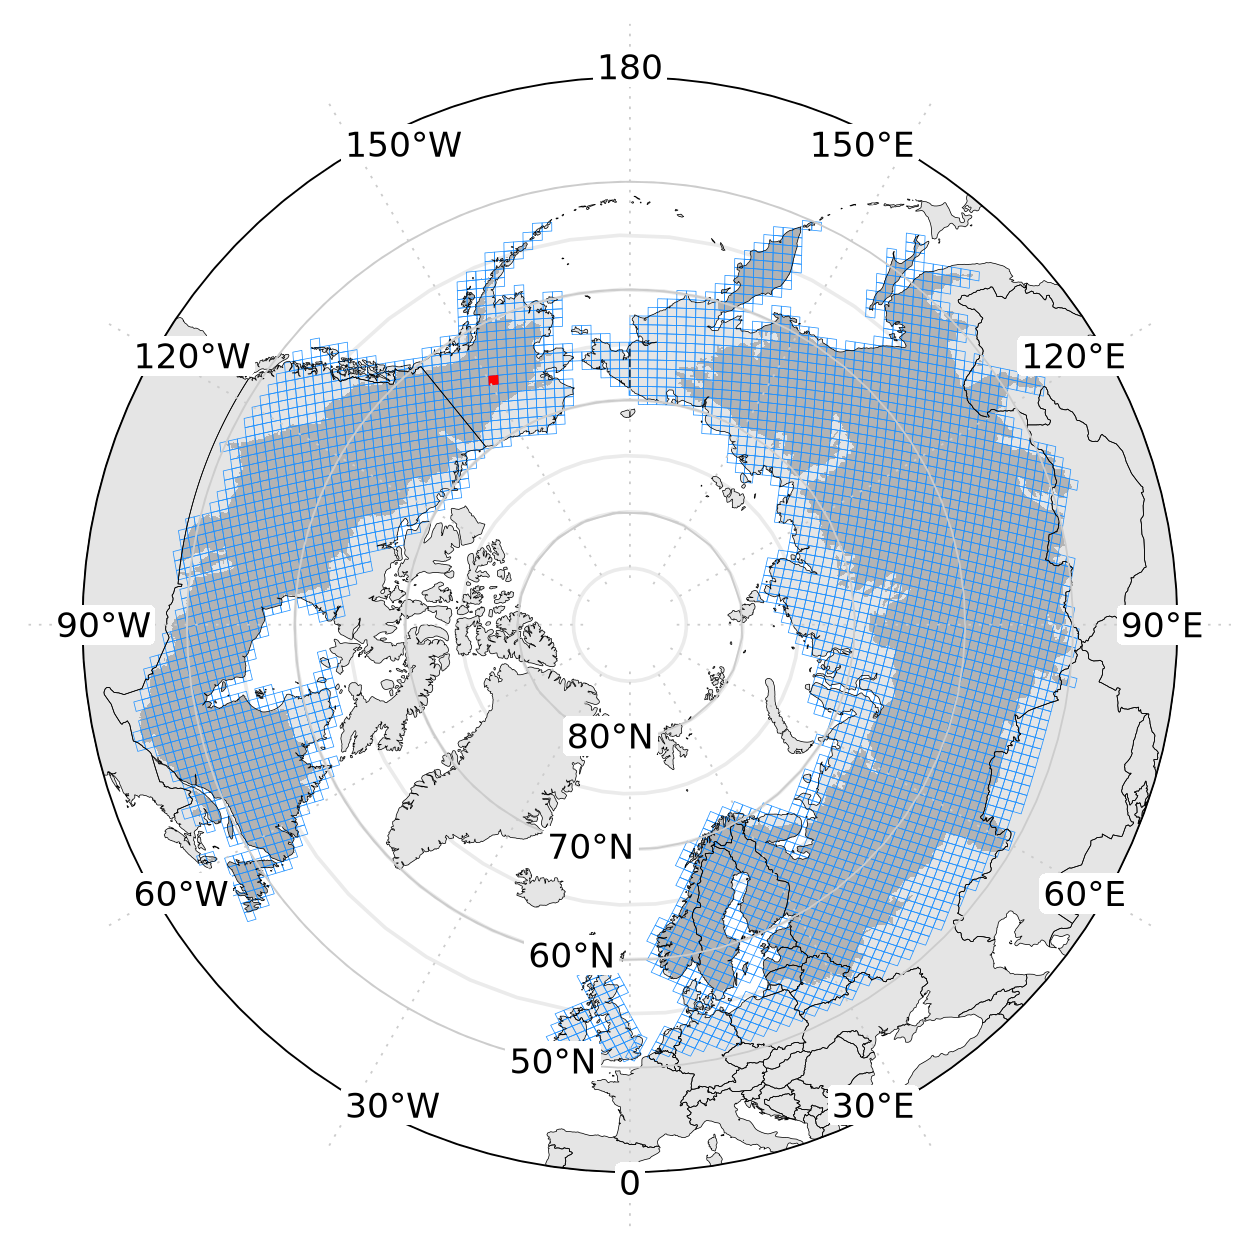

In [49]:
options(repr.plot.width = 5, repr.plot.height = 5, repr.plot.res = 250)

m_boreal_tiles = DO_MAP_BOREAL_SP(MAP_EXTENT=ext,  
                     BOREAL_SHP_FN = wwf_circ_dis_fn,
                     LAYER_LIST = list(
                         geom_polygon(data = boreal_tiles_DAAC_gcs, aes(x = long, y = lat, group = group), size=0.1, fill=NA, color='dodgerblue'),
                         geom_polygon(data = boreal_tiles_DAAC_gcs %>% filter(tile_num == TILE_NUM), aes(x = long, y = lat, group = group), size=0.1, fill='red', color='red')
                     ) #, fill=NA
                    ) + 
    theme(legend.text=element_text(size=rel(0.5)))
m_boreal_tiles

In [8]:
raster_read_proj_convert <- function(fn, BOREAL_MAP='CACC'){
    
    raster_proj <- rast(fn)    
    r <- project(raster_proj, "EPSG:4326")
    
    # Convert raster to data frame
    r_df <- as.data.frame(r, xy = TRUE)
    
    if(BOREAL_MAP == 'AGB'){
        names(r_df)[names(r_df) == 'lyr1'] <- 'prediction mean'
        names(r_df)[names(r_df) == 'sd']   <- 'prediction standard deviation'
        }
    if(BOREAL_MAP == 'AGE'){
        names(r_df)   <- c('x','y','prediction mean', 'prediction standard deviation')
        }
    if(BOREAL_MAP == 'CACC'){
        names(r_df)   <- c('x','y','prediction mean', 'prediction standard deviation', 'ci lower', 'ci upper', 'pi lower', 'pi upper')
        }
    if(BOREAL_MAP == 'TCCTREND'){
        names(r_df)   <- c('x','y','trend')
        }

    return (r_df)
    }

theme_custom = list(
      theme_minimal() +
      theme(
          legend.position="top",
          legend.key.width=unit(2, "cm"),
          legend.key.height=unit(0.5, "cm"),
          legend.text=element_text(size=rel(1))
      ),
          annotation_scale(location = "bl", style="ticks") ,
          #annotation_scale(location = "bl", style="box") ,
          annotation_north_arrow(location = "tl", which_north = "true", style=north_arrow_minimal())
    )
guides_agb= list(
            guides(
                    fill=guide_colourbar(
                             title=paste0("2020 ","Aboveground Woody Biomass Density [Mg/ha]"),
                            title.position = "top", label.position = "bottom", 
                             )
         )
    )
guides_age= list(
            guides(
                    fill=guide_colourbar(
                             title=paste0("2020 ","Forest Age [yr]"),
                            title.position = "top", label.position = "bottom", 
                             )
         )
    )
guides_cacc = list(
            guides(
                    fill=guide_colourbar(
                             title=paste0("2020 ","Carbon accumulation [MgC/ha/yr]"),
                            title.position = "top", label.position = "bottom", 
                             )
          )
    )
guides_trend = list(
            guides(
                    fill=guide_colourbar(
                             title=paste0("1984-2020 ","Tree canopy cover trend [%/yr]"),
                            title.position = "top", label.position = "bottom", 
                            #keywidth = unit(.05, "cm"), keyheight = unit(.25, "cm"), nrow=1
                             )
          )
    )

In [55]:
library(jsonlite)
library(aws.s3)


Attaching package: ‘jsonlite’


The following object is masked from ‘package:purrr’:

    flatten




### Read data

In [ ]:
extent = 'tile'
TILE_NUM_str = str_pad(TILE_NUM, 7, pad = "0")
TILE_NUM_str

In [ ]:
# Set the working directory to where the CSV files are located
setwd(paste0(OUTDIR,"/",extent,'/',TILE_NUM_str))

In [66]:
library(jsonlite)
library(aws.s3)
library(RColorBrewer)

In [85]:
input_raster_fn_json <- fromJSON("input_data.json")
input_raster_fn_json

$topo_cog_fn
[1] "s3://maap-ops-workspace/montesano/dps_output/run_build_stack_topo/build_stack_v2024_2/CopernicusGLO30/2024/07/09/16/36/32/971801/CopernicusGLO30_3201_cog_topo_stack.tif"

$landcover_cog_fn
[1] "s3://maap-ops-workspace/montesano/dps_output/run_build_stack/build_stack_v2023/LC_ESA_WC_2020/2023/12/07/06/40/00/850149/esa_worldcover_v100_2020_3201_cog.tif"

$biomass_cog_fn
[1] "s3://maap-ops-workspace/aliz237/dps_output/run_boreal_biomass_map/dev_v1.5/AGB_H30_2020/full_run/2024/11/25/16/48/22/716711/boreal_agb_2020_202411251732577802_0003201.tif"

$height_cog_fn
[1] "s3://maap-ops-workspace/aliz237/dps_output/run_boreal_biomass_map/dev_v1.5/Ht_H30_2020/full_run/2025/01/13/12/58/20/804292/boreal_ht_2020_202501131736796306_0003201.tif"

$standage_cog_fn
[1] "s3://maap-ops-workspace/montesano/dps_output/run_build_stack/build_stack_v2023_2/FORESTAGE_BES_2020/2025/03/12/07/30/22/437002/FORESTAGE_BES_2020_3201_cog.tif"

$tcc2020_cog_fn
[1] "s3://maap-ops-workspace/montesano/dps_output/run_build_stack/build_stack_v2023_2/TCC_TP_2020/2024/02/11/13/37/57/993132/tcc2020_3201_cog.tif"

$tccslope_cog_fn
[1] "s3://maap-ops-workspace/montesano/dps_output/run_build_stack/build_stack_v2023_2/TCCTREND_TP_2020/2024/02/11/14/46/25/087139/TCCTREND_TP_2020_3201_cog.tif"

$tccpvalue_cog_fn
[1] "s3://maap-ops-workspace/montesano/dps_output/run_build_stack/build_stack_v2023_2/TCCTRENDPVAL_TP_2020/2025/03/12/11/06/49/780495/TCCTRENDPVAL_TP_2020_3201_cog.tif"

$decidpred_cog_fn
[1] "s3://maap-ops-workspace/montesano/dps_output/run_build_stack/build_stack_v2023_2/DECPRED_AB_2015/2025/03/10/14/56/53/683731/DECPRED_AB_2015_3201_cog.tif"

### Map tile

In [ ]:
p_agb_mean = ggplot(raster_read_proj_convert(input_raster_fn_json$biomass_cog_fn, BOREAL_MAP = 'AGB'),
            aes(x = x, y = y, fill = `prediction mean`)) +
         geom_raster() +
          scale_fill_viridis_c(name = "Value", option = "viridis", limits=c(0,125), oob = scales::oob_squish) +  # Continuous color bar
            annotate("text", x = Inf, y = Inf, label = "mean", hjust = 1.1, vjust = 1.5, size = 5) +
          coord_sf(crs = "EPSG:4326", expand = FALSE) +
          labs(x = "", y = "") +
          theme_custom +
          guides_agb

In [ ]:
p_age_mean = ggplot(raster_read_proj_convert(input_raster_fn_json$standage_cog_fn, BOREAL_MAP = 'AGE'),
            aes(x = x, y = y, fill = `prediction mean`)) +
         geom_raster() +
          scale_fill_viridis_c(name = "Value", option = "turbo", limits=c(0,250), oob = scales::oob_squish) +  # Continuous color bar
            annotate("text", x = Inf, y = Inf, label = "mean", hjust = 1.1, vjust = 1.5, size = 5) +
          coord_sf(crs = "EPSG:4326", expand = FALSE) +
          labs(x = "", y = "") +
          theme_custom +
          guides_age

In [ ]:
p_tcctrend = ggplot(raster_read_proj_convert(input_raster_fn_json$tccslope_cog_fn, BOREAL_MAP = 'TCCTREND'),
            aes(x = x, y = y, fill = `trend`)) +
         geom_raster() +
          scale_fill_distiller( direction = 1, 
                    palette = "BrBG",  # Brown-Blue-Green diverging palette
                    limits = c(-2, 2), # Set limits
                    oob = scales::oob_squish, # Squish out-of-bounds values
                    name = "Value") +  # Continuous color bar
          annotate("text", x = Inf, y = Inf, label = "ols slope", hjust = 1.1, vjust = 1.5, size = 5) +
          coord_sf(crs = "EPSG:4326", expand = FALSE) +
          labs(x = "", y = "") +
          theme_custom +
          guides_trend

In [ ]:
p_cacc_mean = ggplot(raster_read_proj_convert(paste0("boreal_cacc_2020_",TILE_NUM_str,".tif"), BOREAL_MAP = 'CACC')%>% filter(`prediction mean` > 0),
            aes(x = x, y = y, fill = `prediction mean`)) +
         geom_raster() +
          scale_fill_viridis_c(name = "Value", option = "plasma", limits=c(0,0.5), oob = scales::oob_squish) +  # Continuous color bar
            annotate("text", x = Inf, y = Inf, label = "mean", hjust = 1.1, vjust = 1.5, size = 5) +
          coord_sf(crs = "EPSG:4326", expand = FALSE) +
          labs(x = "", y = "") +
          theme_custom +
          guides_cacc

In [ ]:
options(repr.plot.width = 18, repr.plot.height = 5, repr.plot.res = 250)

p_agb_mean | p_age_mean | p_cacc_mean | p_tcctrend

### pixel_data, summary_data...

In [ ]:
# Function to add count labels
add_count_labels <- function(p, count_data, Y_VAL=1.95) {
  p + geom_text(
    data = count_data,
    aes(label = paste0('n=',count), y = Y_VAL, angle = 90),  # Position near top of plot (0-2 range)
    position = position_dodge(width = 0.8),
    vjust = -0.5,
    size = 2.5
  )
}

# 1. Read the pixel data sample
pixel_data <- read_csv(paste0("pixel_data_sample_",TILE_NUM_str,".csv")) %>%
  # Convert class columns to ordered factors to maintain specified order
  mutate(
    age_class = factor(age_class, 
                      levels = c('non-forest','1-20', '21-36', '37-60', '61-80', '81-100', '101-150', '>150'),
                      ordered = TRUE),
    age_cohort = factor(age_cohort, 
                      levels = c('non-forest','re-growth forest','young forest', 'mature forest', 'old-growth forest'),
                      ordered = TRUE),
    trend_class = factor(trend_class,
                        levels = c('decline\n(strong)', 'decline\n(weak)', 'stable', 'increase\n(weak)', 'increase\n(strong)','no trend\navailable'),
                        ordered = TRUE),
    pvalue_class = factor(pvalue_class,
                         levels = c('not sig', 'sig (p<0.05)','no trend\navailable'),
                         ordered = TRUE),
    deciduous_class = factor(deciduous_class,
                            levels = c('conifer', 'mixed', 'deciduous'),
                            ordered = TRUE)
  )

# 2. Read the summary by class
summary_data <-  read_csv(paste0("summary_by_class_",TILE_NUM_str,".csv")) %>%
  # Convert class columns to ordered factors
  mutate(
    age_class = factor(age_class, 
                      levels = c('non-forest','1-20', '21-36', '37-60', '61-80', '81-100', '101-150', '>150'),
                      ordered = TRUE),
    age_cohort = factor(age_cohort, 
                      levels = c('non-forest','re-growth forest','young forest', 'mature forest', 'old-growth forest'),
                      ordered = TRUE),
    trend_class = factor(trend_class,
                        levels = c('decline\n(strong)', 'decline\n(weak)', 'stable', 'increase\n(weak)', 'increase\n(strong)','no trend\navailable'),
                        ordered = TRUE),
    pvalue_class = factor(pvalue_class,
                         levels = c('not sig', 'sig (p<0.05)','no trend\navailable'),
                         ordered = TRUE),
    deciduous_class = factor(deciduous_class,
                            levels = c('conifer', 'mixed', 'deciduous'),
                            ordered = TRUE)
  )

# 3. Read the Monte Carlo totals
monte_carlo_totals <- read_csv(paste0("monte_carlo_totals_",TILE_NUM_str,".csv")) %>%
  # Convert class columns to ordered factors
  mutate(
    age_class = factor(age_class, 
                      levels = c('non-forest','1-20', '21-36', '37-60', '61-80', '81-100', '101-150', '>150'),
                      ordered = TRUE),
    # age_cohort = factor(age_cohort, 
    #                   levels = c('non-forest','re-growth forest','young forest', 'mature forest', 'old-growth forest'),
    #                   ordered = TRUE),
    trend_class = factor(trend_class,
                        levels = c('decline\n(strong)', 'decline\n(weak)', 'stable', 'increase\n(weak)', 'increase\n(strong)','no trend\navailable'),
                        ordered = TRUE),
    pvalue_class = factor(pvalue_class,
                         levels = c('not sig', 'sig (p<0.05)','no trend\navailable'),
                         ordered = TRUE),
    deciduous_class = factor(deciduous_class,
                            levels = c('conifer', 'mixed', 'deciduous'),
                            ordered = TRUE)
  )

# 4. Read the age class summary
age_class_summary <- read_csv(paste0("age_class_summary_",TILE_NUM_str,".csv")) %>%
  mutate(age_class = factor(age_class, 
                           levels = c('non-forest','1-20', '21-36', '37-60', '61-80', '81-100', '101-150', '>150'),
                           ordered = TRUE))

# Define color palettes - matching those used in Python
age_colors <- c(
    'non-forest' = 'gray',
    're-growth forest' = '#e41a1c',
    'young forest' = '#d9ef8b',
    'mature forest' = '#5aae61',
    'old-growth forest' = '#1b7837'
)
trend_colors <- c(
  'decline\n(strong)' = '#a6611a',
  'decline\n(weak)' = '#dfc27d',
  'stable' = '#f5f5f5',
  'increase\n(weak)' = '#80cdc1',
  'increase\n(strong)' = '#018571',
  'no trend\navailable' = 'black'
)

pvalue_colors <- c(
        'not sig' = '#fc8d59',
        'sig (p<0.05)' = '#91bfdb',
        'no trend\navailable' = 'black'
)

deciduous_colors <- c(
  'conifer' = '#5e3c99', 
  'mixed' = '#fdb863',
  'deciduous' = '#ffffbf'
)

### Plot data

In [ ]:
# Create output directory for R plots
#dir.create("r_plots", showWarnings = FALSE)

# Calculate count by group for annotations
count_by_age_trend <- pixel_data %>%
  group_by(age_class, trend_class) %>%
  summarise(count = n(), .groups = 'drop')

count_by_age_pvalue <- pixel_data %>%
  group_by(age_class, pvalue_class) %>%
  summarise(count = n(), .groups = 'drop')

count_by_age_deciduous <- pixel_data %>%
  group_by(age_class, deciduous_class) %>%
  summarise(count = n(), .groups = 'drop')

# 1. Carbon accumulation by age class and trend class
p1 <- ggplot(pixel_data, aes(x = age_class, y = carbon_acc, fill = trend_class)) +
  geom_boxplot(position = position_dodge(width = 0.8), outlier.size = 1) +
  scale_fill_manual(values = trend_colors) +
  labs(
    x = 'Age Class (years)',
    y = 'Carbon Accumulation (Mg C/ha/year)',
    fill = 'Canopy Trend',
    title = 'Carbon Accumulation by Age and Canopy Trend'
  ) +
  ylim(0, 2) +
  theme_bw() +
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1),
    legend.position = "right"
  )

# Add count labels
p1 <- add_count_labels(p1, count_by_age_trend)

# Save the plot
ggsave("r_carbon_acc_by_age_trend.png", p1, width = 10, height = 6, dpi = 150, bg='white')

# 2. Carbon accumulation by age class and significance class
p2 <- ggplot(pixel_data, aes(x = age_class, y = carbon_acc, fill = pvalue_class)) +
  geom_boxplot(position = position_dodge(width = 0.8), outlier.size = 1) +
  scale_fill_manual(values = pvalue_colors) +
  labs(
    x = 'Age Class (years)',
    y = 'Carbon Accumulation (Mg C/ha/year)',
    fill = 'Significance',
    title = 'Carbon Accumulation by Age and Statistical Significance'
  ) +
  ylim(0, 2) +
  theme_bw() +
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1),
    legend.position = "right"
  )

# Add count labels
p2 <- add_count_labels(p2, count_by_age_pvalue)

# Save the plot
ggsave("r_carbon_acc_by_age_significance.png", p2, width = 10, height = 6, dpi = 150, bg='white')

# 3. Carbon accumulation by age class and deciduous class
p3 <- ggplot(pixel_data, aes(x = age_class, y = carbon_acc, fill = deciduous_class)) +
  geom_boxplot(position = position_dodge(width = 0.8), outlier.size = 1) +
  scale_fill_manual(values = deciduous_colors) +
  labs(
    x = 'Age Class (years)',
    y = 'Carbon Accumulation (Mg C/ha/year)',
    fill = 'Forest Type',
    title = 'Carbon Accumulation by Age and Forest Type'
  ) +
  ylim(0, 2) +
  theme_bw() +
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1),
    legend.position = "right"
  )

# Add count labels
p3 <- add_count_labels(p3, count_by_age_deciduous)

# Save the plot
ggsave("r_carbon_acc_by_age_forest_type.png", p3, width = 10, height = 6, dpi = 150, bg='white')

# 4. Carbon accumulation confidence intervals by age and trend
# Prepare summary data
summary_age_trend <- pixel_data %>%
  group_by(age_class, trend_class) %>%
  summarise(
    carbon_acc = mean(carbon_acc, na.rm = TRUE),
    carbon_acc_ci_lower = mean(carbon_acc_ci_lower, na.rm = TRUE),
    carbon_acc_ci_upper = mean(carbon_acc_ci_upper, na.rm = TRUE),
    carbon_acc_pi_lower = mean(carbon_acc_pi_lower, na.rm = TRUE),
    carbon_acc_pi_upper = mean(carbon_acc_pi_upper, na.rm = TRUE),
    count = n(),
    .groups = 'drop'
  )

p4 <- ggplot(summary_age_trend, aes(x = age_class, y = carbon_acc, color = trend_class)) +
# geom_pointrange(
#     aes(x = age_class, y = carbon_acc, ymin = carbon_acc_ci_lower, ymax = carbon_acc_ci_upper, color = trend_class),
#     position = position_dodge(width = 0.8)
# ) + 
# geom_errorbar(
#     aes(ymin = carbon_acc_pi_lower, ymax = carbon_acc_pi_upper),
#     width = 1.5, 
#     #position = position_dodge(width = 0.8), 
#     color='black'
#   ) +
geom_errorbar(
    aes(ymin = carbon_acc_ci_lower, ymax = carbon_acc_ci_upper),
    width = 0.25, 
    position = position_dodge(width = 0.8)
  ) +
geom_point(position = position_dodge(width = 0.8), size = 3) +
  scale_color_manual(values = trend_colors) +
  labs(
    x = 'Age Class (years)',
    y = 'Carbon Accumulation (Mg C/ha/year)',
    color = 'Canopy Trend',
    title = 'Carbon Accumulation by Age and Canopy Trend\n(with 95% Confidence Intervals)'
  ) +
  ylim(0, 2.5) +
  theme_bw() +
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1),
    legend.position = "right"
  ) +
  geom_text(
    aes(label = paste0('n=',count), y = 1.95, angle = 90),  # Position near top of plot
    position = position_dodge(width = 0.8),
    vjust = -0.5,
    size = 2.5
  )

# Save the plot
ggsave("r_carbon_acc_ci_by_age_trend.png", p4, width = 10, height = 6, dpi = 150, bg='white')

# 5. Carbon accumulation prediction intervals by age and trend
p5 <- ggplot(summary_age_trend, aes(x = age_class, y = carbon_acc, color = trend_class)) +
  geom_point(position = position_dodge(width = 0.8), size = 3) +
  geom_errorbar(
    aes(ymin = carbon_acc_pi_lower, ymax = carbon_acc_pi_upper),
    width = 0.2, position = position_dodge(width = 0.8)
  ) +
  scale_color_manual(values = trend_colors) +
  labs(
    x = 'Age Class (years)',
    y = 'Carbon Accumulation (Mg C/ha/year)',
    color = 'Canopy Trend',
    title = 'Carbon Accumulation by Age and Canopy Trend (with 95% Prediction Intervals)'
  ) +
  ylim(0, 2) +
  theme_bw() +
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1),
    legend.position = "right"
  ) +
  geom_text(
    aes(label = paste0('n=',count), y = 1.95, angle = 90),  # Position near top of plot
    position = position_dodge(width = 0.8),
    vjust = -0.5,
    size = 2.5
  )

# Save the plot
ggsave("r_carbon_acc_pi_by_age_trend.png", p5, width = 10, height = 6, dpi = 150, bg='white')

# 6. Plot facet grid by all class combinations
# Sample data if too large (similar to Python code)
set.seed(123)  # For reproducibility
subset_data <- pixel_data
if (nrow(pixel_data) > 100000) {
  subset_data <- pixel_data %>% sample_n(100000)
}

# Calculate counts for facet grid
count_by_all <- subset_data %>%
  group_by(age_class, trend_class, pvalue_class, deciduous_class) %>%
  summarise(count = n(), .groups = 'drop')

p6 <- ggplot(subset_data, aes(x = age_class, y = carbon_acc, fill = deciduous_class)) +
  geom_boxplot(position = position_dodge(width = 0.8), outlier.size = 0.5) +
  scale_fill_manual(values = deciduous_colors) +
  facet_grid(trend_class ~ pvalue_class) +
  labs(
    x = 'Age Class (years)',
    y = 'Carbon Accumulation (Mg C/ha/year)',
    fill = 'Forest Type',
    title = 'Carbon Accumulation by Age, Forest Type, Trend, and Significance'
  ) +
  ylim(0, 2) +
  theme_bw() +
  theme(
    axis.text.x = element_text(angle = 90, hjust = 1, size = 8),
    strip.text = element_text(size = 8)
  )

# Note: Adding count to facet plot is more complex
# We'll add aggregate counts by facet
facet_labels <- subset_data %>%
  group_by(trend_class, pvalue_class) %>%
  summarise(count = n(), .groups = 'drop')

# Save the facet grid plot
ggsave("r_carbon_acc_facet_grid.png", p6, width = 10, height = 6, dpi = 150, bg='white')

# 7. Total carbon by age class with confidence intervals
age_summary <- monte_carlo_totals %>%
  group_by(age_class) %>%
  summarise(
    total_carbon_Pg_mean = sum(total_carbon_Pg_mean, na.rm = TRUE),
    total_carbon_Pg_ci_lower = sum(total_carbon_Pg_ci_lower, na.rm = TRUE),
    total_carbon_Pg_ci_upper = sum(total_carbon_Pg_ci_upper, na.rm = TRUE),
    count = n(),
    .groups = 'drop'
  )

p7 <- ggplot(age_summary, aes(x = age_class, y = total_carbon_Pg_mean)) +
  geom_bar(stat = 'identity', fill = 'steelblue', alpha = 0.7) +
  geom_errorbar(
    aes(ymin = total_carbon_Pg_ci_lower, ymax = total_carbon_Pg_ci_upper),
    width = 0.2, color = 'black'
  ) +
  geom_text(
    aes(label = paste0('n=',count), y = total_carbon_Pg_mean),
    position = position_stack(vjust = 0.9),
    color = "white",
    size = 3
  ) +
  labs(
    x = 'Age Class (years)',
    y = 'Total Carbon Stock (Pg C)',
    title = 'Total Carbon Stock by Forest Age Class with 95% Confidence Intervals'
  ) +
  theme_bw() +
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1)
  )

# Save the plot
ggsave("r_total_carbon_by_age.png", p7, width = 10, height = 6, dpi = 150, bg='white')

# Print a summary of the data for verification
cat("Dataset summary:\n")
cat("Pixel data rows:", nrow(pixel_data), "\n")
cat("Summary data rows:", nrow(summary_data), "\n")
cat("Monte Carlo totals rows:", nrow(monte_carlo_totals), "\n")

# Print summary of total carbon to console
grand_total <- sum(monte_carlo_totals$total_carbon_Pg_mean, na.rm = TRUE)
grand_total_ci_lower <- sum(monte_carlo_totals$total_carbon_Pg_ci_lower, na.rm = TRUE)
grand_total_ci_upper <- sum(monte_carlo_totals$total_carbon_Pg_ci_upper, na.rm = TRUE)
grand_total_pi_lower <- sum(monte_carlo_totals$total_carbon_Pg_pi_lower, na.rm = TRUE)
grand_total_pi_upper <- sum(monte_carlo_totals$total_carbon_Pg_pi_upper, na.rm = TRUE)

cat("\n===== CARBON ANALYSIS RESULTS =====\n")
cat(sprintf("Total Carbon Stock: %.9f Pg C\n", grand_total))
cat(sprintf("95%% Confidence Interval: (%.9f, %.9f) Pg C\n", 
            grand_total_ci_lower, grand_total_ci_upper))
cat(sprintf("95%% Prediction Interval: (%.9f, %.9f) Pg C\n", 
            grand_total_pi_lower, grand_total_pi_upper))

In [ ]:
options(repr.plot.width = 12, repr.plot.height = 3, repr.plot.res = 250)

p_bars_age_trend = ggplot(summary_data , aes( x=trend_class, y=total_carbon_Pg, fill=age_cohort) ) +
    geom_bar(stat='identity') + # for a regular bar plot - fast
    scale_fill_manual(values=age_colors, name='Age cohort')+ 
    facet_wrap(.~ pvalue_class, ncol=3, scales='free_x') + 
    theme_bw() +
    labs(y='Total C [Pg]', x='1984-2020 tree cover trend class')
p_bars_age_trend

# Get Carbon accumulations of the mature, young, re-growth that are increasing vs decreasing

In [1]:
options(repr.plot.width = 8, repr.plot.height = 3, repr.plot.res = 250)

count_by_age_cohort <- pixel_data %>%
  group_by(age_cohort) %>%
  summarise(count = n(), .groups = 'drop')

p_violin_c_accum_all = ggplot(pixel_data , aes( x=age_cohort, y=carbon_acc, fill=age_cohort) ) +
    geom_boxplot(outlier.size=0.25, outlier.alpha=0.05) +
    coord_cartesian(ylim=c(0, 1.5)) +
    scale_fill_manual(values=age_colors, name='Age cohort', guide=FALSE)+ 
    #scale_color_manual(values=age_colors, name='Age cohort', guide=FALSE)+ 
    #facet_wrap(.~ deciduous_class, ncol=3, scales='free_x') + 
    #facet_grid(deciduous_class~pvalue_class, scales='free_x') + 
    theme_bw() +
    labs(y='C Accumulation [MgC/ha/yr]', x='Age cohort (forest demography)', caption=TILE_NUM)

p_violin_c_accum_all = add_count_labels(p_violin_c_accum_all, count_by_age_cohort, Y_VAL=1.0)

p_violin_c_accum_all

ERROR: Error in pixel_data %>% group_by(age_cohort) %>% summarise(count = n(), : could not find function "%>%"


In [ ]:
options(repr.plot.width = 14, repr.plot.height = 5, repr.plot.res = 250)

p_violin_c_accum = ggplot(pixel_data %>% filter(age_cohort != 'non-forest'), aes( x=trend_class, y=carbon_acc, fill=age_cohort) ) +
    geom_violin() +
    coord_cartesian(ylim=c(0,1.0)) +
    scale_fill_manual(values=age_colors, name='Age cohort')+ 
    scale_color_manual(values=age_colors, name='Age cohort', guide=FALSE)+ 
    #facet_wrap(.~ deciduous_class, ncol=3, scales='free_x') + 
    facet_grid(deciduous_class~pvalue_class, scales='free_x') + 

    theme_bw() +
    labs(y='C Accumulation [MgC/ha/yr]', x='1984-2020 tree cover trend class')
p_violin_c_accum

In [ ]:
options(repr.plot.width = 14, repr.plot.height = 7, repr.plot.res = 250)

p1

In [ ]:
options(repr.plot.width = 15, repr.plot.height = 4, repr.plot.res = 250)

p_basic <- ggplot(pixel_data, aes(x = age, y = biomass)) +
  #geom_bin2d() +
  geom_hex() +
  scale_fill_viridis(name = "count", trans = "log", option='turbo',
                        breaks = c(1e1,1e3,1e5,1e6)) +
  #scale_color_manual(values = age_colors) +
  labs(
    x = 'Age (years)',
    y = 'AGB (Mg/ha)',
    color = 'Canopy Trend',
    title = 'AGB vs Age'
  ) +
  ylim(0, 125) +
  theme_bw() +
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1),
    legend.position = "right"
  ) + 
facet_grid(.~trend_class)

p_basic

In [ ]:
options(repr.plot.width = 14, repr.plot.height = 7, repr.plot.res = 250)

p5

In [ ]:
options(repr.plot.width = 25, repr.plot.height = 20, repr.plot.res = 250)
# (p1 + p2 + p3) | (p4 + p5 + p6 + p7)
( (p1 / p2 / p3) | ( (p4) / (p6 | p7) ) ) / ( p_bars_age_trend / p_violin_c_accum )